# Multi-task EfficientNet-B3: eye laterality + image centre + DR grade (0-4)
**Data:** APTOS2019 + MULTIMODAL images, `combined_dataset.csv` (laterality, centre, patient id) and the DR-grade files that come with the two datasets.

**What the model predicts (one EfficientNet-B3, three heads) and shows a confidence % for each:**

| Head | Classes | Labels come from |
|---|---|---|
| Laterality | left / right | `combined_dataset.csv` (all images) |
| Image centre | macula / optic_disc | `combined_dataset.csv` (all images) |
| DR grade | 0 No DR, 1 Mild, 2 Moderate, 3 Severe, 4 Proliferative | the grade files inside the datasets (CORAL ordinal head). Images with no grade label are **not** used for this head (no invented labels) but still train the other two heads |

**Changes compared with the old notebook** (details in `KAGGLE_GUIDE.md`)
1. `combined_dataset.csv` is now the master list of images. It is matched to the real Kaggle files and every mismatch is reported.
2. One backbone, three heads, a masked grade loss, and a model-selection score that uses all three tasks.
3. Split is grouped by **patient id** and by near-duplicate images (so one patient / one photo can never be in train and test together).
4. **Augmentation fixed:** random vertical flip removed; horizontal flip now also swaps the left/right label (a mirrored right eye is a left eye).
5. Preprocessed 512px images are cached once, so epochs are not CPU-bound on Kaggle.
6. Confidence % for every head, **temperature calibration** fitted on the validation set, calibration tables / ECE, and a single-image prediction function.

**Before running:** (1) right panel -> *Add Input* -> add your 3 datasets `aptops-2019-only`, `multimodal-dataset-only`, `combined-csv-dataset`; (2) Settings -> Accelerator = GPU (T4 / P100); (3) Settings -> Internet = ON (pretrained weights download). Paths are set in the **first code cell**. Then *Run All*.
*Research prototype - not a clinically validated diagnostic tool.*

In [1]:
import os, re, glob, random, warnings, json
import numpy as np
import pandas as pd
import cv2
from tqdm.auto import tqdm
from multiprocessing.pool import ThreadPool

INPUT = "/kaggle/input"
WORK = "/kaggle/working"
IMG_EXT = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

# ============ STEP 1: YOUR DATASET PATHS (the only place you need to edit) ============
# These are your three Kaggle datasets. Add them with "+ Add Input" (right panel) and the paths below will work as they are.
APTOS_DIR = "/kaggle/input/datasets/binodrajpant13/aptops-2019-only"
MULTI_DIR = "/kaggle/input/datasets/binodrajpant13/multimodal-dataset-only"
CSV_PATH  = "/kaggle/input/datasets/binodrajpant13/combined-csv-dataset/combined_dataset.csv"
# If a path is wrong, step 2 prints the real folder tree and tries to find the folders by itself; copy the right path from that tree.
APTOS_EXCLUDE, MULTI_EXCLUDE = [], []     # sub-folder words to skip (e.g. ["oct"]) if a folder is not fundus photos
USE_MULTI_GRADES = True     # use DR grades of MULTIMODAL if the dataset has them (auto-skipped if it has none)

# ----- training settings -----
SEED = 42
IMG = 512            # input size
BATCH = 8            # if "CUDA out of memory": 4
EPOCHS = 25
PATIENCE = 6         # stop if the selection score does not improve for this many epochs
LR, WD = 3e-4, 1e-4
PREP = "both"        # "ben", "clahe" or "both"
WORKERS = 2          # Kaggle has few CPU cores; images come from the cache so 2 is enough
FLIP_SWAP = True     # horizontal flip + swap left/right label (valid for laterality). False = no flipping at all
W_LAT, W_CEN, W_DR = 1.0, 1.0, 1.0      # loss weights of the three heads
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15   # 75/15/15 adds up to 105%, so 70/15/15 is the default
REVIEW_BELOW = 70.0  # predictions with confidence below this % are flagged "needs review"

LAT_NAMES = ["left", "right"]
CEN_NAMES = ["macula", "optic_disc"]
GRADE_NAMES = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
CACHE = f"{WORK}/cache_{IMG}_{PREP}.npy"

def set_seed(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
set_seed(SEED)

# 2. find the dataset folders and combined_dataset.csv

In [2]:
def show_tree(root, max_depth=4):
    base = root.rstrip("/").count("/")
    for dp, dn, fn in os.walk(root):
        depth = dp.count("/") - base
        if depth > max_depth:
            dn[:] = []
            continue
        dn.sort()
        n_img = sum(f.lower().endswith(IMG_EXT) for f in fn)
        n_csv = sum(f.lower().endswith(".csv") for f in fn)
        print("  " * depth + os.path.basename(dp) + f"/   [{n_img} images, {n_csv} csv]")

def find_dir(keyword, max_depth=6):
    hits, base = [], INPUT.count("/")
    for dp, dn, fn in os.walk(INPUT):
        if dp.count("/") - base >= max_depth:
            dn[:] = []
            continue
        for d in dn:
            if keyword in d.lower():
                hits.append(os.path.join(dp, d))
    return sorted(hits, key=lambda p: (p.count("/"), p))

def find_file(name, max_depth=6):
    base = INPUT.count("/")
    for dp, dn, fn in os.walk(INPUT):
        if dp.count("/") - base >= max_depth:
            dn[:] = []
            continue
        if name in fn:
            return os.path.join(dp, name)
    return None

show_tree(INPUT)
if not (APTOS_DIR and os.path.isdir(APTOS_DIR)):
    print("APTOS_DIR not found -> searching /kaggle/input ...")
    h = find_dir("aptos") + find_dir("aptops");   APTOS_DIR = h[0] if h else None
if not (MULTI_DIR and os.path.isdir(MULTI_DIR)):
    print("MULTI_DIR not found -> searching /kaggle/input ...")
    h = find_dir("multimodal");                   MULTI_DIR = h[0] if h else None
if not (CSV_PATH and os.path.isfile(CSV_PATH)):
    print("CSV_PATH not found -> searching /kaggle/input ...")
    CSV_PATH = find_file("combined_dataset.csv")
    if CSV_PATH is None:                                   # same dataset, different file name
        d = find_dir("combined-csv") + find_dir("combined_csv")
        c = sorted(glob.glob(os.path.join(d[0], "**", "*.csv"), recursive=True)) if d else []
        CSV_PATH = c[0] if c else None
print("\nAPTOS_DIR:", APTOS_DIR)
print("MULTI_DIR:", MULTI_DIR)
print("CSV_PATH :", CSV_PATH)
assert APTOS_DIR and MULTI_DIR, "Could not find a dataset folder. Fix APTOS_DIR / MULTI_DIR in the first code cell using the tree printed above."
assert CSV_PATH, "csv not found. Add the combined-csv-dataset input or fix CSV_PATH in the first code cell."

input/   [0 images, 0 csv]
  datasets/   [0 images, 0 csv]
    binodrajpant13/   [0 images, 0 csv]
      aptops-2019-only/   [0 images, 3 csv]
        test_images/   [0 images, 0 csv]
        train_images/   [0 images, 0 csv]
        val_images/   [0 images, 0 csv]
      combined-csv-dataset/   [0 images, 1 csv]
      multimodal-dataset-only/   [0 images, 1 csv]
        Imagenes/   [0 images, 0 csv]

APTOS_DIR: /kaggle/input/datasets/binodrajpant13/aptops-2019-only
MULTI_DIR: /kaggle/input/datasets/binodrajpant13/multimodal-dataset-only
CSV_PATH : /kaggle/input/datasets/binodrajpant13/combined-csv-dataset/combined_dataset.csv


# 3. read combined_dataset.csv and match every row to a real image file

In [3]:
def list_images(root, exclude=()):
    out = []
    for dp, _, fn in os.walk(root):
        for f in fn:
            p = os.path.join(dp, f)
            rel = p[len(root):].lower()
            if f.lower().endswith(IMG_EXT) and not any(w.lower() in rel for w in exclude):
                out.append(p)
    return sorted(out)

meta = pd.read_csv(CSV_PATH)
need = {"dataset", "patient_id", "centre", "laterality", "image_name"}
assert need <= set(meta.columns), f"csv must have columns {need}, found {list(meta.columns)}"
for c in ["dataset", "centre", "laterality", "image_name"]:
    meta[c] = meta[c].astype(str).str.strip()
meta["dataset"] = meta.dataset.str.upper()
meta["centre"] = meta.centre.str.lower()
meta["laterality"] = meta.laterality.str.lower()
assert set(meta.laterality) <= set(LAT_NAMES), f"unexpected laterality values: {set(meta.laterality)}"
assert set(meta.centre) <= set(CEN_NAMES), f"unexpected centre values: {set(meta.centre)}"
assert set(meta.dataset) <= {"APTOS", "MULTIMODAL"}, f"unexpected dataset values: {set(meta.dataset)}"
assert not meta.image_name.duplicated().any(), "duplicate image_name rows in the csv"
meta["lat_y"] = meta.laterality.map({n: i for i, n in enumerate(LAT_NAMES)})
meta["cen_y"] = meta.centre.map({n: i for i, n in enumerate(CEN_NAMES)})
print("csv rows:", len(meta))
print(pd.crosstab(meta.dataset, [meta.centre, meta.laterality]))

class Resolver:
    # csv name "APTOS2019/train_images/train_images/x.png": drop the first folder, match the rest below the dataset folder
    def __init__(self, root, exclude):
        self.by_rel, self.by_base = {}, {}
        for p in list_images(root, exclude):
            self.by_rel[os.path.relpath(p, root).replace(os.sep, "/").lower()] = p
            self.by_base.setdefault(os.path.basename(p).lower(), []).append(p)
        self.n = len(self.by_rel)
    def find(self, name):
        parts = name.replace("\\", "/").lower().split("/")
        rel = "/".join(parts[1:])
        if rel in self.by_rel:
            return self.by_rel[rel]
        c = self.by_base.get(parts[-1], [])
        return c[0] if len(c) == 1 else None          # file-name fallback only when the name is unique

res = {"APTOS": Resolver(APTOS_DIR, APTOS_EXCLUDE), "MULTIMODAL": Resolver(MULTI_DIR, MULTI_EXCLUDE)}
print({k: f"{v.n} image files on disk" for k, v in res.items()})
meta["path"] = [res[d].find(n) for d, n in zip(meta.dataset, meta.image_name)]
miss = meta[meta.path.isna()]
print(f"\nmatched {meta.path.notna().sum()} / {len(meta)} csv rows to files")
if len(miss):
    print("NOT FOUND (first 8):"); print(miss[["dataset", "image_name"]].head(8).to_string(index=False))
    assert len(miss) / len(meta) < 0.05, "more than 5% of the csv rows have no image file: check APTOS_DIR / MULTI_DIR / the folder tree"
    print("dropping", len(miss), "unmatched rows")
meta = meta[meta.path.notna()].reset_index(drop=True)
assert not meta.path.duplicated().any(), "two csv rows point to the same file"

csv rows: 4117
centre     macula       optic_disc      
laterality   left right       left right
dataset                                 
APTOS        1641  1823        128    70
MULTIMODAL    233   213          2     7
{'APTOS': '3662 image files on disk', 'MULTIMODAL': '455 image files on disk'}

matched 4117 / 4117 csv rows to files


# 4. DR grades (0-4) from the grade files that come with the datasets

In [4]:
ID_NAMES = ("id_code", "image", "image_id", "imageid", "id", "filename", "file_name", "file",
            "name", "image_name", "img", "path", "image_path")
LABEL_NAMES = ("diagnosis", "label", "level", "grade", "dr_grade", "dr", "class", "severity",
               "retinopathy_grade", "dr_level")

def to_grade(v):
    # turn a csv value or folder name into a DR grade 0-4 (None if it is not a grade)
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    try:
        f = float(v)
        return int(f) if f == int(f) and 0 <= f <= 4 else None
    except (ValueError, TypeError):
        pass
    s = str(v).lower().strip()
    m = re.fullmatch(r"(?:grade|class|level|dr|stage)?[_\- ]?([0-4])", s)
    if m:
        return int(m.group(1))
    if "severe" in s:   return 3
    if "moderate" in s: return 2
    if "mild" in s:     return 1
    if "prolif" in s:   return 4
    if re.match(r"^(no[_\- ]?dr|normal|healthy|no[_\- ]?diabetic|no[_\- ]?retinopathy)", s):
        return 0
    return None

def grade_table(name, root, exclude=()):
    # returns DataFrame(path, label) for images that have a grade. Nothing is invented: no grade -> not in the table
    imgs = list_images(root, exclude)
    lookup = {}
    for p in imgs:
        rel = os.path.relpath(p, root).replace(os.sep, "/").lower()
        base = os.path.basename(p).lower()
        for key in (rel, base, os.path.splitext(base)[0]):
            lookup.setdefault(key, p)
    print(f"\n=== grade files for {name} ({len(imgs)} images under {root})")
    parts = []
    for c in sorted(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True)):
        try:
            d = pd.read_csv(c)
        except Exception:
            continue
        cols = {re.sub(r"[ \-]+", "_", x.strip().lower()): x for x in d.columns}
        idc = next((cols[n] for n in ID_NAMES if n in cols), None)
        lbc = next((cols[n] for n in LABEL_NAMES if n in cols), None)
        if idc is None or lbc is None:
            print("  skip csv (no id/grade column):", os.path.relpath(c, root), list(d.columns)[:6])
            continue
        prefer_test = "test" in os.path.basename(c).lower()     # IDRiD-style test images are stored as <name>test.jpg
        def resolve(k):
            k = str(k).strip().lower().replace("\\", "/")
            b = os.path.basename(k); stem = os.path.splitext(b)[0]
            cand = ([stem + "test"] if prefer_test else []) + [k, b, stem]
            return next((lookup[x] for x in cand if x in lookup), None)
        paths = d[idc].map(resolve)
        rate = paths.notna().mean()
        print(f"  {os.path.relpath(c, root)}: id='{idc}' grade='{lbc}' rows={len(d)} matched={rate:.0%}")
        if rate < 0.5:
            continue
        parts.append(pd.DataFrame({"path": paths, "label": d[lbc].map(to_grade)}).dropna())
    if not parts:
        print("  -> no usable grade file found for", name)
        return pd.DataFrame({"path": [], "label": []})
    tab = pd.concat(parts, ignore_index=True)
    clash = int((tab.groupby("path").label.nunique() > 1).sum())
    if clash:
        print("  WARNING: images with conflicting grades across csv files:", clash, "(they are removed from grade training)")
        bad = set(tab.groupby("path").filter(lambda g: g.label.nunique() > 1).path)
        tab = tab[~tab.path.isin(bad)]
    tab = tab.drop_duplicates("path")
    tab["label"] = tab.label.astype(int)
    print("  grades per class:", tab.label.value_counts().sort_index().to_dict())
    return tab.reset_index(drop=True)

g_a = grade_table("APTOS", APTOS_DIR, APTOS_EXCLUDE)
g_m = grade_table("MULTIMODAL", MULTI_DIR, MULTI_EXCLUDE) if USE_MULTI_GRADES else pd.DataFrame({"path": [], "label": []})
gmap = dict(zip(pd.concat([g_a, g_m]).path, pd.concat([g_a, g_m]).label))
meta["grade"] = meta.path.map(gmap).fillna(-1).astype(int)      # -1 = no grade label (head 3 ignores these images)

cov = meta.assign(has=meta.grade >= 0).groupby("dataset").has.agg(["sum", "size"])
cov.columns = ["with_grade", "images"]
print("\ngrade coverage:\n", cov)
assert cov.loc["APTOS", "with_grade"] > 0.9 * cov.loc["APTOS", "images"], \
    "APTOS grades were not found for most images. Read the grade-file printout above and fix the paths."
if cov.loc["MULTIMODAL", "with_grade"] == 0:
    print("NOTE: MULTIMODAL has no usable grade labels -> those images train laterality + centre only.")
print("\ngrade x dataset (-1 = no label):")
print(meta.groupby(["dataset", "grade"]).size().unstack(fill_value=0))


=== grade files for APTOS (3662 images under /kaggle/input/datasets/binodrajpant13/aptops-2019-only)
  test.csv: id='id_code' grade='diagnosis' rows=366 matched=100%
  train_1.csv: id='id_code' grade='diagnosis' rows=2930 matched=100%
  valid.csv: id='id_code' grade='diagnosis' rows=366 matched=100%
  grades per class: {0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}

=== grade files for MULTIMODAL (455 images under /kaggle/input/datasets/binodrajpant13/multimodal-dataset-only)
  idrid_labels.csv: id='id_code' grade='diagnosis' rows=455 matched=100%
  grades per class: {0: 129, 1: 22, 2: 156, 3: 84, 4: 64}

grade coverage:
             with_grade  images
dataset                       
APTOS             3662    3662
MULTIMODAL         455     455

grade x dataset (-1 = no label):
grade          0    1    2    3    4
dataset                             
APTOS       1805  370  999  193  295
MULTIMODAL   129   22  156   84   64


# 5. preprocess every image once (cache) + fingerprint for duplicate detection

In [5]:
def crop_black(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    ys, xs = np.where(gray > 10)
    if len(xs) == 0:
        return img
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def make_square(img):
    h, w = img.shape[:2]
    d = abs(h - w); a, b = d // 2, d - d // 2
    if h > w:
        return cv2.copyMakeBorder(img, 0, 0, a, b, cv2.BORDER_CONSTANT, value=0)
    return cv2.copyMakeBorder(img, a, b, 0, 0, cv2.BORDER_CONSTANT, value=0)

def load_square(path):
    img = cv2.imread(path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(make_square(crop_black(img)), (IMG, IMG))

def enhance(img):
    if PREP in ("ben", "both"):
        blur = cv2.GaussianBlur(img, (0, 0), IMG / 2 / 30)
        img = cv2.addWeighted(img, 4, blur, -4, 128)
    if PREP in ("clahe", "both"):
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
        img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return img

def preprocess(path):
    # same function is used for training (cache), testing and single-image prediction
    sq = load_square(path)
    if sq is None:
        raise RuntimeError(f"cannot read image: {path}")
    return enhance(sq)

def fingerprint(img):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    low = cv2.dct(g)[:8, :8]
    return (low > np.median(low.flatten()[1:])).flatten()        # 64-bit perceptual hash

cv2.setNumThreads(1)
n = len(meta)
meta["cache_idx"] = np.arange(n)
mm = np.lib.format.open_memmap(CACHE, mode="w+", dtype=np.uint8, shape=(n, IMG, IMG, 3))

def work(i):
    sq = load_square(meta.path.iat[i])
    if sq is None:
        return i, None
    mm[i] = enhance(sq)
    return i, fingerprint(sq)

hashes = [None] * n
with ThreadPool(max(2, os.cpu_count() or 2)) as pool:
    for i, h in tqdm(pool.imap_unordered(work, range(n)), total=n):
        hashes[i] = h
mm.flush(); del mm
ok = np.array([h is not None for h in hashes])
if (~ok).any():
    print("unreadable images dropped:", int((~ok).sum()))
meta = meta[ok].reset_index(drop=True)
H = np.array([h for h in hashes if h is not None])
print("cache:", CACHE, "| images:", len(meta), "| size GB:", round(os.path.getsize(CACHE) / 1e9, 2))

  0%|          | 0/4117 [00:00<?, ?it/s]

cache: /kaggle/working/cache_512_both.npy | images: 4117 | size GB: 3.24


# 6. groups: same patient OR near-identical image = same group (never split apart)

In [6]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

n = len(meta)
Hf = H.astype(np.float32); Hn = 1.0 - Hf
pairs_i, pairs_j, pairs_d = [], [], []
CH = 1000
for s in range(0, n, CH):
    e = min(s + CH, n)
    d = 64 - (Hf[s:e] @ Hf.T + Hn[s:e] @ Hn.T)      # hamming distance of every image in the block to every image
    d[np.arange(e - s), np.arange(s, e)] = 99       # ignore itself
    r, c = np.where(d <= 3)
    pairs_i.append(r + s); pairs_j.append(c); pairs_d.append(d[r, c])
pi, pj, pd_ = np.concatenate(pairs_i), np.concatenate(pairs_j), np.concatenate(pairs_d)

def components(edges_i, edges_j):
    g = coo_matrix((np.ones(len(edges_i)), (edges_i, edges_j)), shape=(n, n))
    return connected_components(g, directed=False)[1]

# "same image" = small hamming distance. Retina photos look alike at 32x32, so if a threshold glues many different
# photos into huge groups it is lowered automatically (largest duplicate group must stay <= 25 images).
THRESH = 3
for THRESH in (3, 2, 1, 0):
    lab_dup = components(pi[pd_ <= THRESH], pj[pd_ <= THRESH])
    biggest = np.bincount(lab_dup).max()
    if biggest <= 25:
        break
print(f"duplicate threshold used: {THRESH} (largest duplicate-only group: {biggest} images)")

# same patient -> same group, as well
first, ei, ej = {}, [], []
for i, key in enumerate(zip(meta.dataset, meta.patient_id)):
    if key in first:
        ei.append(first[key]); ej.append(i)
    else:
        first[key] = i
mask = pd_ <= THRESH
grp = components(np.concatenate([pi[mask], ei]).astype(int), np.concatenate([pj[mask], ej]).astype(int))
meta["group_id"] = ["g" + str(x) for x in grp]
sizes = meta.groupby("group_id").size()
print("images:", n, "| groups after duplicates only:", len(set(lab_dup)), "| groups after duplicates + patients:", len(sizes))
print("groups with >1 image:", int((sizes > 1).sum()), "| largest group:", int(sizes.max()))
print("groups spanning both datasets:", int((meta.groupby("group_id").dataset.nunique() > 1).sum()))
lab = meta[meta.grade >= 0]
print("groups whose images have different grades:", int((lab.groupby("group_id").grade.nunique() > 1).sum()),
      "(normal: the two eyes / visits of one patient can differ)")
assert sizes.max() < 0.05 * n, "one group holds >5% of all images; the split would be distorted. Lower THRESH search or check the images"

duplicate threshold used: 1 (largest duplicate-only group: 4 images)
images: 4117 | groups after duplicates only: 3962 | groups after duplicates + patients: 3754
groups with >1 image: 226 | largest group: 36
groups spanning both datasets: 0
groups whose images have different grades: 66 (normal: the two eyes / visits of one patient can differ)


# 7. train / val / test split (grouped, stratified by dataset + grade + centre)

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1) < 1e-9
N_FOLDS = 20                                        # each fold = 5% of the data
n_test, n_val = round(TEST_FRAC * N_FOLDS), round(VAL_FRAC * N_FOLDS)
strat = meta.dataset + "_g" + meta.grade.astype(str) + "_c" + meta.cen_y.astype(str)
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold = np.full(len(meta), -1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for k, (_, idx) in enumerate(sgkf.split(meta, strat, meta.group_id)):
        fold[idx] = k
meta["split"] = np.where(fold < n_test, "test", np.where(fold < n_test + n_val, "val", "train"))
print(meta.split.value_counts(normalize=True).round(3).to_string())
assert (meta.groupby("group_id").split.nunique() == 1).all(), "leakage between splits"
assert (meta.groupby(["dataset", "patient_id"]).split.nunique() == 1).all(), "a patient is in two splits"

print("\nsplit x dataset");    print(meta.groupby(["split", "dataset"]).size().unstack(fill_value=0))
print("\nsplit x laterality"); print(meta.groupby(["split", "laterality"]).size().unstack(fill_value=0))
print("\nsplit x centre");     print(meta.groupby(["split", "centre"]).size().unstack(fill_value=0))
print("\nsplit x grade (-1 = no label)"); print(meta.groupby(["split", "grade"]).size().unstack(fill_value=0))
for s in ("train", "val", "test"):
    sub = meta[meta.split == s]
    assert sub.lat_y.nunique() == 2 and sub.cen_y.nunique() == 2 and (sub.grade >= 0).any(), f"{s} split misses a class"

meta["id_code"] = meta.dataset + "__" + meta.path.map(lambda p: os.path.splitext(os.path.basename(p))[0])
meta.to_csv(f"{WORK}/combined_master.csv", index=False)
print("\nsaved", meta.shape, "->", f"{WORK}/combined_master.csv")

split
train    0.706
val      0.154
test     0.140

split x dataset
dataset  APTOS  MULTIMODAL
split                     
test       503          74
train     2590         316
val        569          65

split x laterality
laterality  left  right
split                  
test         301    276
train       1396   1510
val          307    327

split x centre
centre  macula  optic_disc
split                     
test       546          31
train     2761         145
val        603          31

split x grade (-1 = no label)
grade     0    1    2    3    4
split                          
test    282   60  136   38   61
train  1342  284  838  198  244
val     310   48  181   41   54

saved (4117, 13) -> /kaggle/working/combined_master.csv


# 8. torch setup, dataset, augmentation, loaders

In [8]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from sklearn.metrics import (cohen_kappa_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             recall_score, confusion_matrix)
import matplotlib.pyplot as plt
from IPython.display import clear_output

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
set_seed(SEED)
m_train = meta[meta.split == "train"].reset_index(drop=True)
m_val = meta[meta.split == "val"].reset_index(drop=True)
m_test = meta[meta.split == "test"].reset_index(drop=True)
print(DEVICE, "| train", len(m_train), "| val", len(m_val), "| test", len(m_test))

# NO vertical flip. A horizontal flip turns a right eye into a left eye, so the laterality label is swapped with it.
train_aug = T.Compose([T.RandomRotation(30), T.ColorJitter(brightness=0.2, contrast=0.2)])
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class MTData(Dataset):
    def __init__(self, table, train):
        self.idx = table.cache_idx.values
        self.lat, self.cen, self.grade = table.lat_y.values, table.cen_y.values, table.grade.values
        self.train, self.arr = train, None
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        if self.arr is None:                                    # opened inside each worker
            self.arr = np.load(CACHE, mmap_mode="r")
        x = torch.from_numpy(np.array(self.arr[self.idx[i]])).permute(2, 0, 1)
        lat, cen, g = int(self.lat[i]), int(self.cen[i]), int(self.grade[i])
        if self.train:
            if FLIP_SWAP and torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[2]); lat = 1 - lat
            x = train_aug(x)
        x = (x.float() / 255.0 - MEAN) / STD
        levels = torch.tensor([float(g > k) for k in range(4)]) if g >= 0 else torch.zeros(4)   # ordinal targets
        return x, lat, cen, g, levels

def make_loader(tab, train):
    return DataLoader(MTData(tab, train), batch_size=BATCH, shuffle=train, num_workers=WORKERS,
                      pin_memory=DEVICE == "cuda", drop_last=train, persistent_workers=WORKERS > 0)
train_loader, val_loader, test_loader = make_loader(m_train, True), make_loader(m_val, False), make_loader(m_test, False)
xb, la, ce, gr, lv = next(iter(train_loader))
print(xb.shape, "lat", la[:8].tolist(), "centre", ce[:8].tolist(), "grade", gr[:8].tolist())

cuda | train 2906 | val 634 | test 577
torch.Size([8, 3, 512, 512]) lat [1, 1, 1, 0, 0, 0, 0, 1] centre [0, 0, 0, 0, 0, 0, 0, 0] grade [4, 2, 0, 0, 0, 2, 4, 2]


# 9. model: EfficientNet-B3 + 3 heads, and the loss

In [9]:
class MultiTaskEffNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        try:
            base = torchvision.models.efficientnet_b3(weights="IMAGENET1K_V1" if pretrained else None)
        except Exception as e:
            raise RuntimeError("Could not download the pretrained EfficientNet-B3 weights. "
                               "Turn Internet ON in the Kaggle notebook settings (right panel), then run again.") from e
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.3)
        self.lat_head = nn.Linear(1536, 2)                       # left / right
        self.cen_head = nn.Linear(1536, 2)                       # macula / optic disc
        self.dr_fc = nn.Linear(1536, 1, bias=False)              # CORAL ordinal head: 1 score + 4 ordered biases
        self.dr_bias = nn.Parameter(torch.linspace(1.5, -1.5, 4))
    def forward(self, x):
        h = self.drop(self.pool(self.features(x)).flatten(1))
        return self.lat_head(h), self.cen_head(h), self.dr_fc(h) + self.dr_bias

def inv_freq(y, k):
    c = np.bincount(y, minlength=k).clip(min=1)
    return torch.tensor(len(y) / (k * c), dtype=torch.float32).to(DEVICE)
LAT_W, CEN_W = inv_freq(m_train.lat_y.values, 2), inv_freq(m_train.cen_y.values, 2)
CLASS_W = inv_freq(m_train.grade[m_train.grade >= 0].values, 5)
print("class weights  laterality", LAT_W.cpu().numpy().round(2), "| centre", CEN_W.cpu().numpy().round(2),
      "| grade", CLASS_W.cpu().numpy().round(2))

def mt_loss(out, lat, cen, g, lv):
    lo_lat, lo_cen, lo_dr = out
    l_lat = F.cross_entropy(lo_lat, lat, weight=LAT_W)
    l_cen = F.cross_entropy(lo_cen, cen, weight=CEN_W)
    mask = g >= 0                                                # images without a grade do not train the grade head
    if mask.any():
        bce = F.binary_cross_entropy_with_logits(lo_dr[mask], lv[mask], reduction="none").sum(1)
        l_dr = (bce * CLASS_W[g[mask]]).mean()
    else:
        l_dr = lo_dr.sum() * 0.0
    return W_LAT * l_lat + W_CEN * l_cen + W_DR * l_dr, (l_lat.item(), l_cen.item(), l_dr.item())

class weights  laterality [1.04 0.96] | centre [ 0.53 10.02] | grade [0.43 2.05 0.69 2.94 2.38]


# 10. helpers: prediction, confidence, metrics

In [10]:
def softmax_np(z, T=1.0):
    z = z / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def coral_cp(logits, T=1.0):
    # CORAL threshold logits (N,4) -> probability of each grade (N,5)
    p = 1 / (1 + np.exp(-logits / T))
    cp = np.zeros((len(p), 5))
    cp[:, 0] = 1 - p[:, 0]
    for k in range(1, 4):
        cp[:, k] = p[:, k - 1] - p[:, k]
    cp[:, 4] = p[:, 3]
    cp = np.clip(cp, 1e-6, None)
    return cp / cp.sum(1, keepdims=True)

def grade_pred(logits):
    return (logits > 0).sum(1)              # number of thresholds passed (sigmoid>0.5 <=> logit>0)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    A, B, C, Y = [], [], [], []
    for x, lat, cen, g, _ in loader:
        with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
            a, b, c = model(x.to(DEVICE, non_blocking=True))
        A.append(a.float().cpu()); B.append(b.float().cpu()); C.append(c.float().cpu())
        Y.append(torch.stack([lat, cen, g], 1))
    Y = torch.cat(Y).numpy()
    return dict(lat=torch.cat(A).numpy(), cen=torch.cat(B).numpy(), dr=torch.cat(C).numpy(),
                y_lat=Y[:, 0], y_cen=Y[:, 1], y_gr=Y[:, 2])

def val_scores(P):
    # per-head accuracy / confidence + the model-selection score
    r = {}
    for key, ylab in (("lat", "y_lat"), ("cen", "y_cen")):
        pr = softmax_np(P[key]); pred = pr.argmax(1)
        r[f"{key}_acc"] = 100 * (pred == P[ylab]).mean()
        r[f"{key}_bacc"] = 100 * balanced_accuracy_score(P[ylab], pred)
        r[f"{key}_conf"] = 100 * pr.max(1).mean()
    mk = P["y_gr"] >= 0
    pg = grade_pred(P["dr"][mk]); cp = coral_cp(P["dr"][mk])
    r["dr_acc"] = 100 * (pg == P["y_gr"][mk]).mean()
    r["dr_conf"] = 100 * cp[np.arange(len(pg)), pg].mean()
    r["dr_qwk"] = float(np.nan_to_num(cohen_kappa_score(P["y_gr"][mk], pg, weights="quadratic")))
    r["score"] = (r["dr_qwk"] + r["lat_bacc"] / 100 + r["cen_bacc"] / 100) / 3     # selects the best epoch
    return r

def live_view(log):
    d = pd.DataFrame(log).round(3)
    clear_output(wait=True)
    print(d[["epoch", "train_loss", "lat_acc", "cen_bacc", "dr_acc", "dr_qwk", "score"]].to_string(index=False))
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.4))
    ax[0].plot(d.epoch, d.train_loss, marker="o"); ax[0].set_title("train loss")
    ax[1].plot(d.epoch, d.lat_acc, marker="o", label="laterality acc %")
    ax[1].plot(d.epoch, d.cen_bacc, marker="o", label="centre balanced acc %"); ax[1].legend(); ax[1].set_title("val laterality / centre")
    ax[2].plot(d.epoch, d.dr_qwk, marker="o", color="tab:green", label="grade QWK")
    ax[2].plot(d.epoch, d.score, marker="o", color="k", label="selection score"); ax[2].legend(); ax[2].set_title("val grade QWK / score")
    for k, c in (("lat", "tab:blue"), ("cen", "tab:orange"), ("dr", "tab:green")):
        ax[3].plot(d.epoch, d[f"{k}_conf"], color=c, label=f"{k} confidence %")
        ax[3].plot(d.epoch, d[f"{k}_acc"], color=c, ls="--", label=f"{k} accuracy %")
    ax[3].legend(fontsize=7); ax[3].set_title("val confidence vs accuracy")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def train_model(seed):
    set_seed(seed)
    model = MultiTaskEffNet().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    best, bad, log = -1, 0, []
    save_to = f"{WORK}/effb3_multitask_best.pt"
    for ep in range(EPOCHS):
        model.train()
        tot, seen = 0.0, 0
        bar = tqdm(train_loader, desc=f"epoch {ep+1}/{EPOCHS}", leave=False)
        for x, lat, cen, g, lv in bar:
            x, lat, cen, g, lv = [t.to(DEVICE, non_blocking=True) for t in (x, lat, cen, g, lv)]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
                out = model(x)
            loss, parts = mt_loss(tuple(o.float() for o in out), lat, cen, g, lv)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(x); seen += len(x)
            bar.set_postfix(loss=f"{tot/seen:.3f}", lat=f"{parts[0]:.2f}", cen=f"{parts[1]:.2f}", dr=f"{parts[2]:.2f}")
        r = val_scores(predict(model, val_loader))
        log.append(dict(epoch=ep + 1, train_loss=tot / seen, **r))
        live_view(log)
        if r["score"] > best:
            best, bad = r["score"], 0
            torch.save(model.state_dict(), save_to)
            print(f"epoch {ep+1}: new best score {best:.4f} -> saved")
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stop"); break
    print("best selection score:", round(best, 4))
    return save_to, log

# 11. run training

 epoch  train_loss  lat_acc  cen_bacc  dr_acc  dr_qwk  score
     1       3.366   82.492    64.102  23.028   0.659  0.710
     2       2.395   98.580    83.825  63.091   0.849  0.891
     3       1.857   99.369    88.934  67.192   0.838  0.907
     4       1.680   99.685    80.848  72.397   0.870  0.892
     5       1.598   99.685    84.858  70.662   0.881  0.909
     6       1.517   99.211    90.601  67.981   0.848  0.915
     7       1.419   99.527    92.757  71.293   0.876  0.933
     8       1.352   99.211    83.660  70.347   0.865  0.898
     9       1.262   98.896    88.536  67.981   0.863  0.913
    10       1.193   99.685    75.309  65.615   0.850  0.867
    11       1.155   99.685    85.107  70.662   0.858  0.902
    12       1.053   99.211    92.425  73.502   0.873  0.930
    13       0.992   99.211    79.484  71.136   0.877  0.888


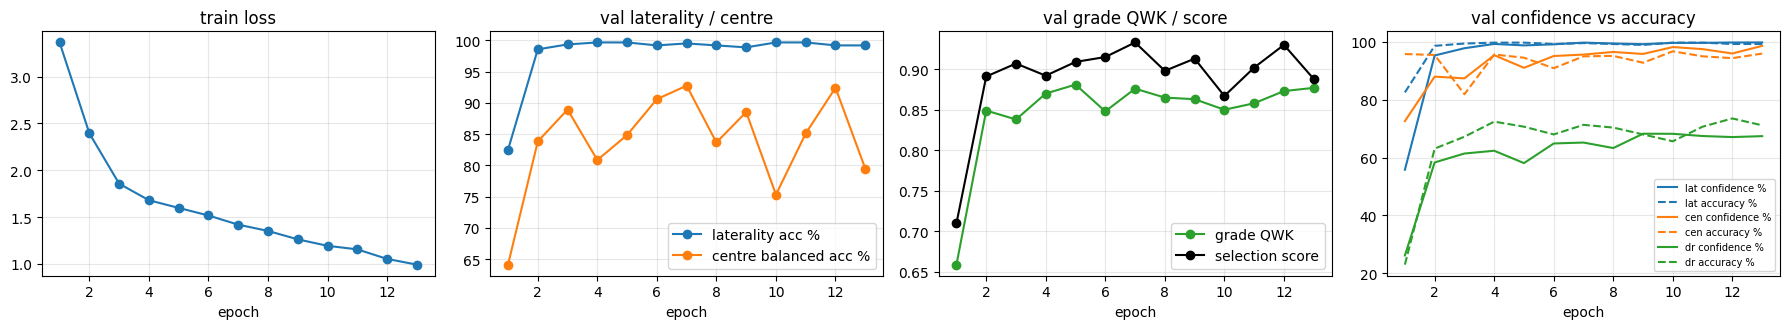

early stop
best selection score: 0.933


In [11]:
, history = train_model(SEED)
pd.DataFrame(history).to_csv(f"{WORK}/effb3_multitask_log.csv", index=False)

# 12. test results for each head (combined test split, then per dataset)

In [12]:
model = MultiTaskEffNet(pretrained=False).to(DEVICE)
model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
Pv, Pt = predict(model, val_loader), predict(model, test_loader)

def report_binary(title, names, logits, y, mask=None):
    mask = np.ones(len(y), bool) if mask is None else mask
    pr = softmax_np(logits[mask]); pred = pr.argmax(1); yy = y[mask]
    print(f"\n--- {title} (n={len(yy)}) ---")
    print("accuracy      :", round((pred == yy).mean(), 4), "| balanced acc:", round(balanced_accuracy_score(yy, pred), 4),
          "| macro F1:", round(f1_score(yy, pred, average="macro"), 4))
    if len(np.unique(yy)) == 2:
        print("AUC           :", round(roc_auc_score(yy, pr[:, 1]), 4))
    print("recall per class:", dict(zip(names, recall_score(yy, pred, labels=[0, 1], average=None, zero_division=0).round(3))))
    print("confusion matrix (rows = true, cols = predicted", names, ")\n", confusion_matrix(yy, pred, labels=[0, 1]))

def report_grade(title, y, logits, mask=None):
    mask = (y >= 0) if mask is None else (mask & (y >= 0))
    yy, lg = y[mask], logits[mask]
    p, c = grade_pred(lg), coral_cp(lg)
    print(f"\n--- {title} (n={len(yy)}) ---")
    print("accuracy      :", round((p == yy).mean(), 4), "| QWK:", round(cohen_kappa_score(yy, p, weights="quadratic"), 4),
          "| balanced acc:", round(balanced_accuracy_score(yy, p), 4), "| macro F1:", round(f1_score(yy, p, average="macro"), 4))
    try:
        print("macro AUC (ovr):", round(roc_auc_score(yy, c, multi_class="ovr", labels=[0, 1, 2, 3, 4]), 4))
    except ValueError:
        print("macro AUC (ovr): not computable (a grade is missing in this subset)")
    print("per-grade sensitivity:", dict(zip(range(5), recall_score(yy, p, labels=[0, 1, 2, 3, 4], average=None, zero_division=0).round(3))))
    print("confusion matrix (rows = true grade, cols = predicted)\n", confusion_matrix(yy, p, labels=[0, 1, 2, 3, 4]))
    rt, rp = yy >= 2, p >= 2
    if rt.sum() and (~rt).sum():
        print("referable DR (grade>=2) sensitivity / specificity:", round((rp & rt).sum() / rt.sum(), 3), round((~rp & ~rt).sum() / (~rt).sum(), 3))

report_binary("LATERALITY - all test", LAT_NAMES, Pt["lat"], Pt["y_lat"])
report_binary("IMAGE CENTRE - all test", CEN_NAMES, Pt["cen"], Pt["y_cen"])
report_grade("DR GRADE - all test (graded images only)", Pt["y_gr"], Pt["dr"])
for ds in m_test.dataset.unique():
    mk = (m_test.dataset == ds).values
    report_binary(f"LATERALITY - {ds}", LAT_NAMES, Pt["lat"], Pt["y_lat"], mk)
    report_binary(f"IMAGE CENTRE - {ds}", CEN_NAMES, Pt["cen"], Pt["y_cen"], mk)
    if ((Pt["y_gr"] >= 0) & mk).sum() > 0:
        report_grade(f"DR GRADE - {ds}", Pt["y_gr"], Pt["dr"], mk)


--- LATERALITY - all test (n=577) ---
accuracy      : 0.9965 | balanced acc: 0.9967 | macro F1: 0.9965
AUC           : 0.9999
recall per class: {'left': np.float64(0.993), 'right': np.float64(1.0)}
confusion matrix (rows = true, cols = predicted ['left', 'right'] )
 [[299   2]
 [  0 276]]

--- IMAGE CENTRE - all test (n=577) ---
accuracy      : 0.9359 | balanced acc: 0.8444 | macro F1: 0.7598
AUC           : 0.9211
recall per class: {'macula': np.float64(0.947), 'optic_disc': np.float64(0.742)}
confusion matrix (rows = true, cols = predicted ['macula', 'optic_disc'] )
 [[517  29]
 [  8  23]]

--- DR GRADE - all test (graded images only) (n=577) ---
accuracy      : 0.7002 | QWK: 0.8903 | balanced acc: 0.5502 | macro F1: 0.536
macro AUC (ovr): 0.9044
per-grade sensitivity: {0: np.float64(0.979), 1: np.float64(0.483), 2: np.float64(0.36), 3: np.float64(0.289), 4: np.float64(0.639)}
confusion matrix (rows = true grade, cols = predicted)
 [[276   6   0   0   0]
 [  8  29  18   5   0]
 [  5

# 13. confidence % + calibration
Confidence = probability the model gives to the class it predicted (softmax for laterality / centre, CORAL class probability for the grade).
Raw network probabilities are often over-confident, so one **temperature** per head is fitted on the *validation* set (it never changes which class is predicted, only how sure the model says it is). Calibration is then checked on the *test* set.

In [13]:
def nll_binary(z, y, T):
    p = softmax_np(z, T)[np.arange(len(y)), y]
    return -np.log(np.clip(p, 1e-9, None)).mean()

def nll_grade(z, y, T):
    p = coral_cp(z, T)[np.arange(len(y)), y]
    return -np.log(np.clip(p, 1e-9, None)).mean()

grid = np.linspace(0.3, 5.0, 95)
mv = Pv["y_gr"] >= 0
T_LAT = float(grid[np.argmin([nll_binary(Pv["lat"], Pv["y_lat"], t) for t in grid])])
T_CEN = float(grid[np.argmin([nll_binary(Pv["cen"], Pv["y_cen"], t) for t in grid])])
T_DR = float(grid[np.argmin([nll_grade(Pv["dr"][mv], Pv["y_gr"][mv], t) for t in grid])])
TEMPS = {"lat": T_LAT, "cen": T_CEN, "dr": T_DR}
print("fitted temperatures (1.0 = no change, >1 = model was over-confident):", {k: round(v, 2) for k, v in TEMPS.items()})

def ece_table(conf, correct, bins=(0, 50, 60, 70, 80, 90, 95, 100.01)):
    b = pd.cut(conf, list(bins), right=False)
    t = pd.DataFrame({"conf": conf, "ok": correct}).groupby(b, observed=True).agg(
        n=("ok", "size"), mean_conf=("conf", "mean"), accuracy=("ok", lambda x: 100 * x.mean())).round(1)
    return t, (t.n * (t.mean_conf - t.accuracy).abs()).sum() / t.n.sum()

def build_output(P, tab, T=None):
    T = T or {"lat": 1.0, "cen": 1.0, "dr": 1.0}
    pl, pc = softmax_np(P["lat"], T["lat"]), softmax_np(P["cen"], T["cen"])
    pg, cp = grade_pred(P["dr"]), coral_cp(P["dr"], T["dr"])
    o = tab[["id_code", "dataset", "patient_id", "group_id"]].copy().reset_index(drop=True)
    o["lat_true"] = [LAT_NAMES[i] for i in P["y_lat"]]; o["lat_pred"] = [LAT_NAMES[i] for i in pl.argmax(1)]
    o["lat_conf_%"] = (100 * pl.max(1)).round(2)
    o["cen_true"] = [CEN_NAMES[i] for i in P["y_cen"]]; o["cen_pred"] = [CEN_NAMES[i] for i in pc.argmax(1)]
    o["cen_conf_%"] = (100 * pc.max(1)).round(2)
    o["grade_true"] = P["y_gr"]; o["grade_pred"] = pg; o["grade_name"] = [GRADE_NAMES[i] for i in pg]
    o["grade_conf_%"] = (100 * cp[np.arange(len(pg)), pg]).round(2)
    for k in range(5):
        o[f"p_grade{k}_%"] = (100 * cp[:, k]).round(2)
    o["lat_ok"] = o.lat_true == o.lat_pred; o["cen_ok"] = o.cen_true == o.cen_pred
    o["grade_ok"] = np.where(o.grade_true >= 0, o.grade_true == o.grade_pred, np.nan)
    o["needs_review"] = (o[["lat_conf_%", "cen_conf_%", "grade_conf_%"]].min(1) < REVIEW_BELOW)
    return o

out_raw, out = build_output(Pt, m_test), build_output(Pt, m_test, TEMPS)
out.to_csv(f"{WORK}/effb3_multitask_test_predictions.csv", index=False)

print("\n=== calibration on the TEST set (confidence bin vs real accuracy), before -> after temperature scaling ===")
for name, col_c, col_ok, mask in (("LATERALITY", "lat_conf_%", "lat_ok", None), ("IMAGE CENTRE", "cen_conf_%", "cen_ok", None),
                                  ("DR GRADE", "grade_conf_%", "grade_ok", out.grade_true >= 0)):
    for tag, o in (("raw", out_raw), ("calibrated", out)):
        oo = o if mask is None else o[mask]
        t, e = ece_table(oo[col_c].values, oo[col_ok].astype(bool).values)
        if tag == "calibrated":
            print(f"\n{name} ({tag}) | mean confidence {oo[col_c].mean():.1f}% | accuracy {100*oo[col_ok].astype(bool).mean():.1f}% | ECE {e:.1f} points")
            print(t.to_string())
        else:
            print(f"\n{name} ({tag}): ECE {e:.1f} points")

print("\nfirst 12 test images:")
print(out[["id_code", "lat_true", "lat_pred", "lat_conf_%", "cen_true", "cen_pred", "cen_conf_%",
           "grade_true", "grade_pred", "grade_conf_%", "needs_review"]].head(12).to_string(index=False))
print(f"\nimages flagged for human review (any confidence < {REVIEW_BELOW}%):", int(out.needs_review.sum()), "of", len(out))

fitted temperatures (1.0 = no change, >1 = model was over-confident): {'lat': 0.95, 'cen': 1.2, 'dr': 0.65}

=== calibration on the TEST set (confidence bin vs real accuracy), before -> after temperature scaling ===

LATERALITY (raw): ECE 0.4 points

LATERALITY (calibrated) | mean confidence 99.7% | accuracy 99.7% | ECE 0.4 points
                  n  mean_conf  accuracy
[50.0, 60.0)      1  55.200001       0.0
[60.0, 70.0)      1  62.900002     100.0
[70.0, 80.0)      1  72.500000     100.0
[90.0, 95.0)      4  92.800003     100.0
[95.0, 100.01)  570  99.900002      99.8

IMAGE CENTRE (raw): ECE 2.2 points

IMAGE CENTRE (calibrated) | mean confidence 93.8% | accuracy 93.6% | ECE 2.3 points
                  n  mean_conf  accuracy
[50.0, 60.0)     10  56.099998      50.0
[60.0, 70.0)     13  64.199997      46.2
[70.0, 80.0)     33  76.099998      69.7
[80.0, 90.0)     54  85.300003      90.7
[90.0, 95.0)     82  92.699997      96.3
[95.0, 100.01)  385  98.800003      98.2

DR GRADE (ra

# 14. 95% confidence intervals (bootstrap over patient/duplicate groups)

In [14]:
B = 1000
rs = np.random.default_rng(SEED)
gid = m_test.group_id.values
groups = pd.Series(np.arange(len(gid))).groupby(gid).apply(np.array).tolist()
lat_p, cen_p, gr_p = Pt["lat"].argmax(1), Pt["cen"].argmax(1), grade_pred(Pt["dr"])

def metrics(idx):
    r = {"laterality accuracy": (lat_p[idx] == Pt["y_lat"][idx]).mean(),
         "laterality balanced acc": balanced_accuracy_score(Pt["y_lat"][idx], lat_p[idx]),
         "centre balanced acc": balanced_accuracy_score(Pt["y_cen"][idx], cen_p[idx])}
    ig = idx[Pt["y_gr"][idx] >= 0]
    r["grade accuracy"] = (gr_p[ig] == Pt["y_gr"][ig]).mean()
    r["grade QWK"] = cohen_kappa_score(Pt["y_gr"][ig], gr_p[ig], weights="quadratic")
    return r

point = metrics(np.arange(len(gid)))
runs = {k: [] for k in point}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _ in tqdm(range(B)):
        pick = rs.integers(0, len(groups), len(groups))
        for k, v in metrics(np.concatenate([groups[i] for i in pick])).items():
            runs[k].append(v)
ci = pd.DataFrame([(k, round(100 * point[k], 2), *np.round(100 * np.nanpercentile(runs[k], [2.5, 97.5]), 2)) for k in point],
                  columns=["metric", "value_%", "ci95_low_%", "ci95_high_%"])
print(ci.to_string(index=False))
ci.to_csv(f"{WORK}/effb3_multitask_test_ci.csv", index=False)

  0%|          | 0/1000 [00:00<?, ?it/s]

                 metric  value_%  ci95_low_%  ci95_high_%
    laterality accuracy    99.65       99.13       100.00
laterality balanced acc    99.67       99.17       100.00
    centre balanced acc    84.44       76.37        91.86
         grade accuracy    70.02       66.09        73.88
              grade QWK    89.03       86.93        90.93


# 15. see the confidence: predict any image + save the model for later use
`predict_image(path)` prints the result in the format your supervisor asked for (laterality, centre, grade with confidence %) and draws the bars.

4ed31cc07366.png
  Eye laterality : right      Confidence: 100.0%
  Image centre   : macula     Confidence: 91.8%
  DR severity    : Grade 2 (Moderate)   Confidence: 37.0%
  -> at least one confidence is below 70.0%: needs human review


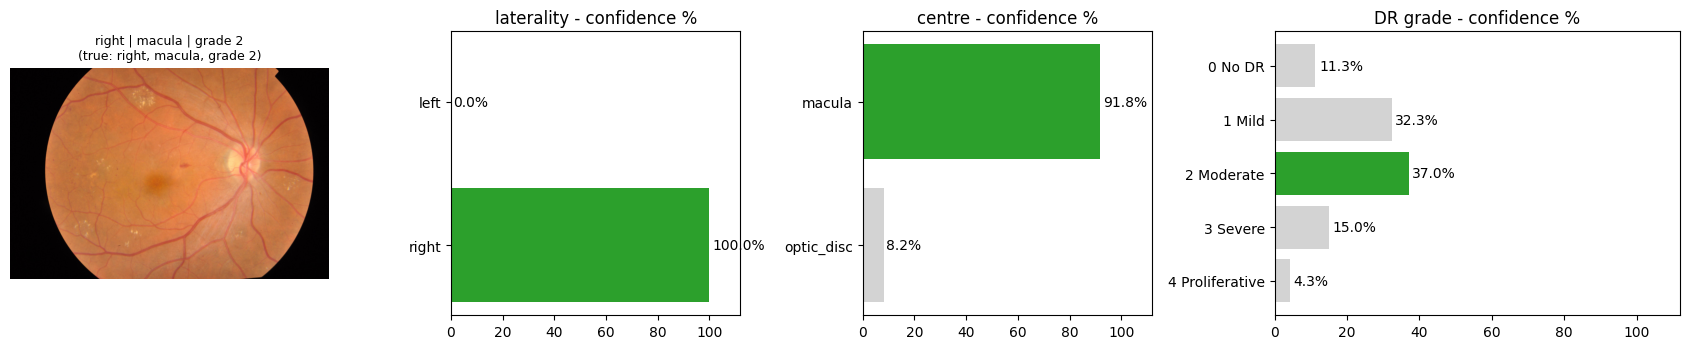

dc0f6e5b489b.png
  Eye laterality : right      Confidence: 99.9%
  Image centre   : macula     Confidence: 96.1%
  DR severity    : Grade 0 (No DR)   Confidence: 99.9%


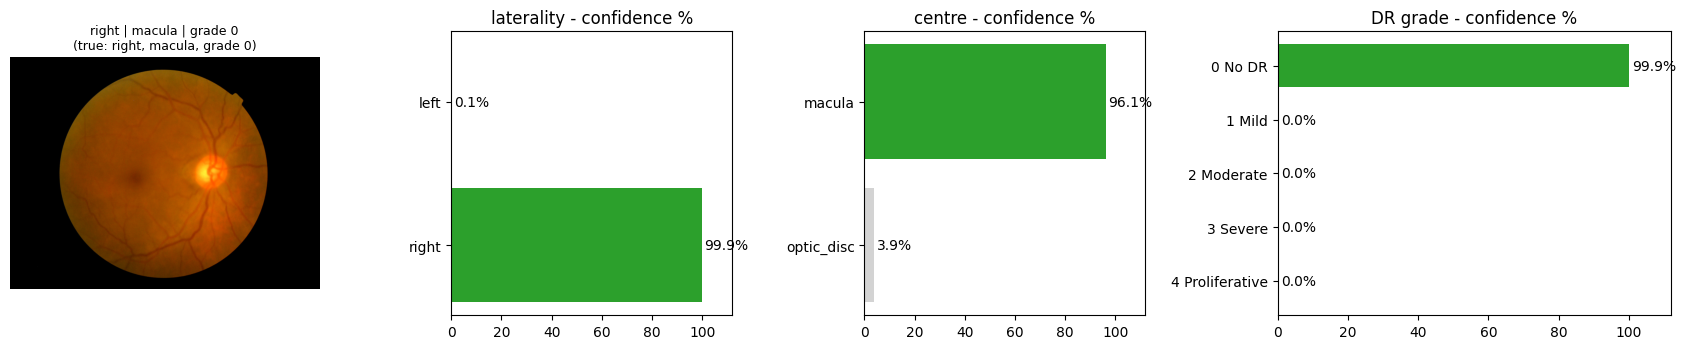

IDRiD_032.jpg
  Eye laterality : left       Confidence: 100.0%
  Image centre   : macula     Confidence: 99.7%
  DR severity    : Grade 3 (Severe)   Confidence: 35.3%
  -> at least one confidence is below 70.0%: needs human review


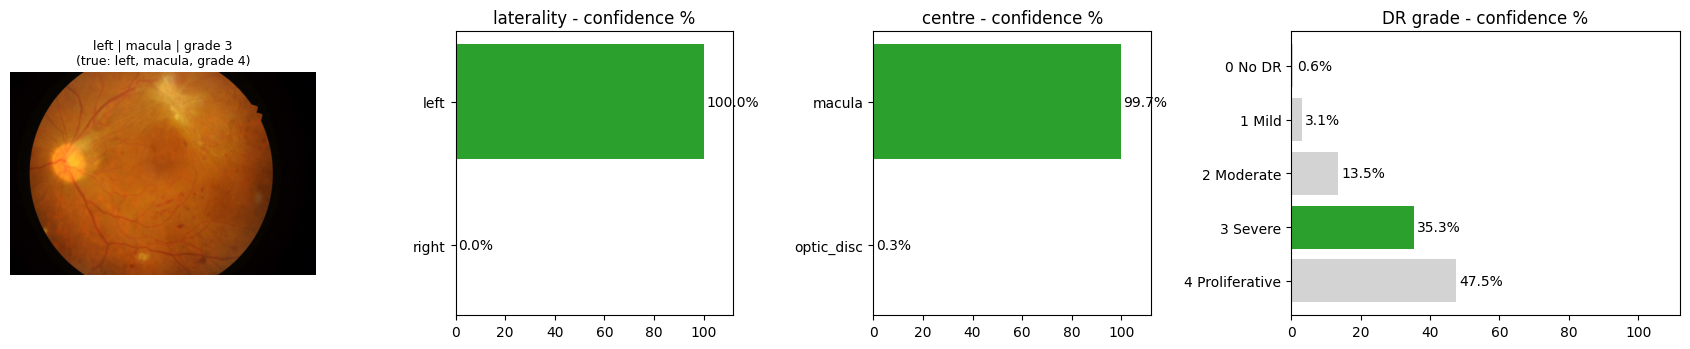

467b7d9d811c.png
  Eye laterality : left       Confidence: 99.9%
  Image centre   : macula     Confidence: 99.9%
  DR severity    : Grade 2 (Moderate)   Confidence: 37.1%
  -> at least one confidence is below 70.0%: needs human review


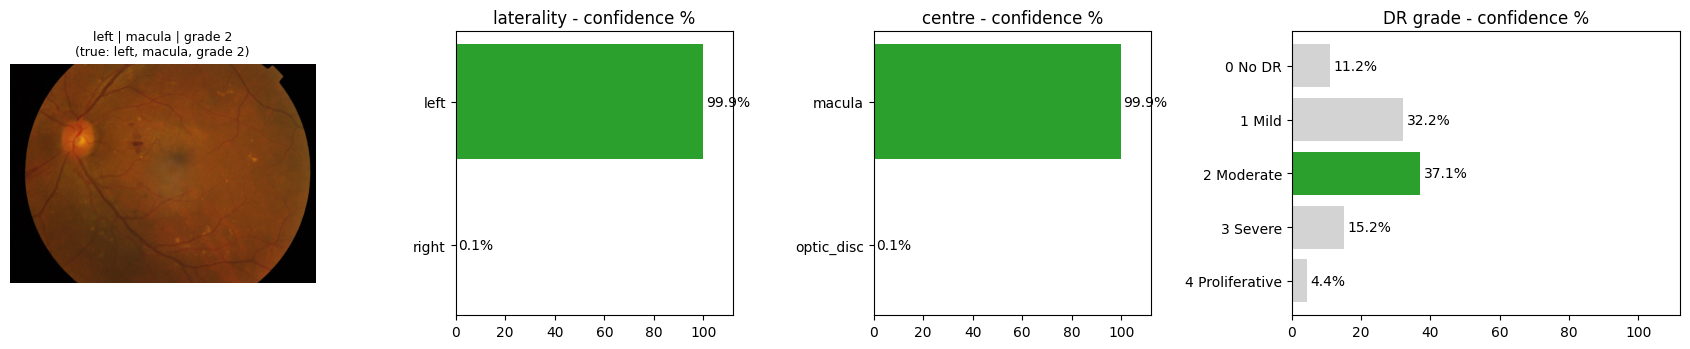

0fb560f9adb2.png
  Eye laterality : left       Confidence: 99.6%
  Image centre   : macula     Confidence: 99.8%
  DR severity    : Grade 3 (Severe)   Confidence: 38.5%
  -> at least one confidence is below 70.0%: needs human review


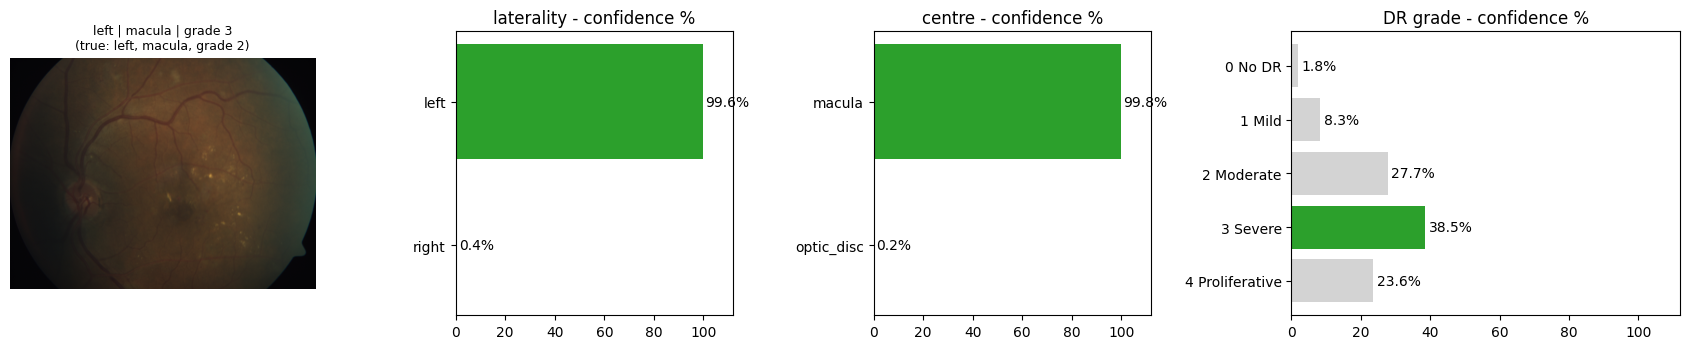

5eb8fb1aad41.png
  Eye laterality : left       Confidence: 98.1%
  Image centre   : optic_disc Confidence: 99.9%
  DR severity    : Grade 0 (No DR)   Confidence: 100.0%


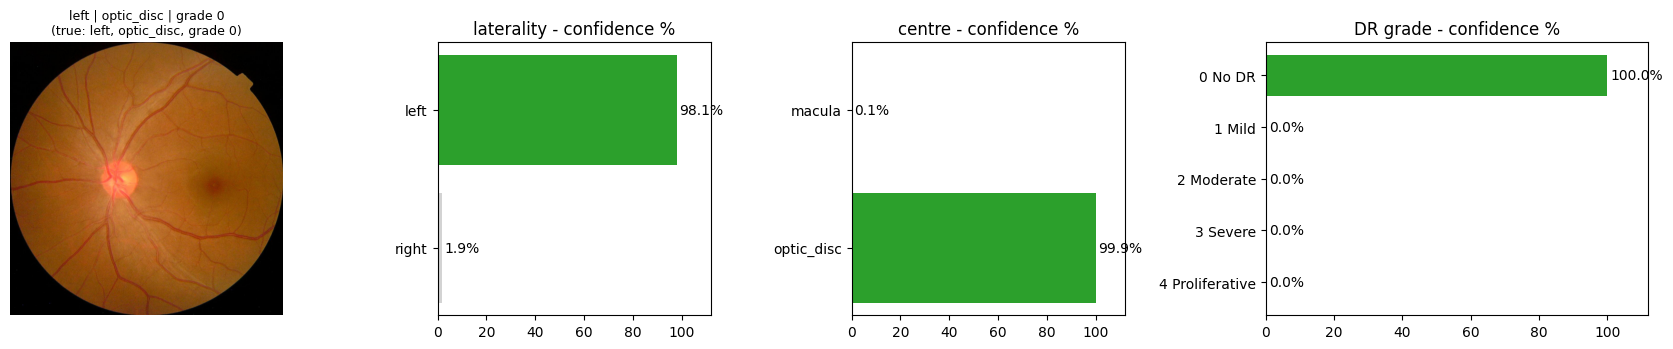

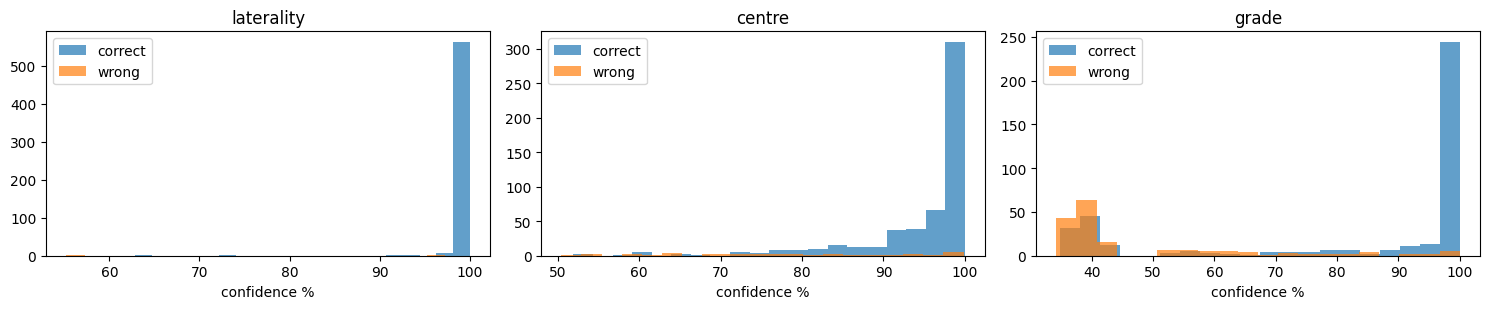

saved: ['.virtual_documents', 'effb3_multitask_test_predictions.csv', 'effb3_multitask_test_ci.csv', 'effb3_multitask_log.csv', 'cache_512_both.npy', 'effb3_multitask_bundle.pt', 'effb3_multitask_best.pt', 'effb3_multitask_confidence_hist.png', 'combined_master.csv']


In [15]:
def predict_image(path, true=None, show=True):
    x = torch.from_numpy(preprocess(path)).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad(), torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
        a, b, c = model(x)
    a, b, c = a.float().cpu().numpy(), b.float().cpu().numpy(), c.float().cpu().numpy()
    pl, pc = softmax_np(a, TEMPS["lat"])[0] * 100, softmax_np(b, TEMPS["cen"])[0] * 100
    cp = coral_cp(c, TEMPS["dr"])[0] * 100
    g = int(grade_pred(c)[0]); li, ci_ = int(pl.argmax()), int(pc.argmax())
    res = dict(laterality=LAT_NAMES[li], laterality_conf=pl[li], centre=CEN_NAMES[ci_], centre_conf=pc[ci_],
               grade=g, grade_name=GRADE_NAMES[g], grade_conf=cp[g], grade_probs=cp)
    if show:
        print(f"{os.path.basename(path)}\n"
              f"  Eye laterality : {res['laterality']:<10} Confidence: {pl[li]:.1f}%\n"
              f"  Image centre   : {res['centre']:<10} Confidence: {pc[ci_]:.1f}%\n"
              f"  DR severity    : Grade {g} ({res['grade_name']})   Confidence: {cp[g]:.1f}%")
        if min(pl[li], pc[ci_], cp[g]) < REVIEW_BELOW:
            print(f"  -> at least one confidence is below {REVIEW_BELOW}%: needs human review")
        fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.1, 1, 1, 1.4]})
        ax[0].imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)); ax[0].axis("off")
        ax[0].set_title(f"{LAT_NAMES[li]} | {CEN_NAMES[ci_]} | grade {g}" + (f"\n(true: {true})" if true else ""), fontsize=9)
        for a_, names, pr, k, t in ((ax[1], LAT_NAMES, pl, li, "laterality"), (ax[2], CEN_NAMES, pc, ci_, "centre"),
                                    (ax[3], [f"{j} {GRADE_NAMES[j]}" for j in range(5)], cp, g, "DR grade")):
            a_.barh(names, pr, color=["tab:green" if j == k else "lightgray" for j in range(len(names))])
            a_.set_xlim(0, 112); a_.invert_yaxis(); a_.set_title(t + " - confidence %")
            for j, v in enumerate(pr): a_.text(v + 1, j, f"{v:.1f}%", va="center")
        plt.tight_layout(); plt.show()
    return res

# 6 random test images (true labels shown)
for _, r in m_test.sample(min(6, len(m_test)), random_state=SEED).iterrows():
    predict_image(r.path, true=f"{r.laterality}, {r.centre}, grade {r.grade if r.grade >= 0 else 'n/a'}")

# your own image: upload it as a Kaggle dataset or use a path inside the datasets, then uncomment
# predict_image("/kaggle/input/<your-dataset>/<your-image>.png")

# confidence when right vs wrong, per head
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for a_, (t, c, ok, mk) in zip(ax, (("laterality", "lat_conf_%", "lat_ok", out.lat_ok.notna()), ("centre", "cen_conf_%", "cen_ok", out.cen_ok.notna()),
                                    ("grade", "grade_conf_%", "grade_ok", out.grade_true >= 0))):
    o = out[mk]; good = o[ok].astype(bool)
    a_.hist(o.loc[good, c], bins=20, alpha=0.7, label="correct"); a_.hist(o.loc[~good, c], bins=20, alpha=0.7, label="wrong")
    a_.set_title(t); a_.set_xlabel("confidence %"); a_.legend()
plt.tight_layout(); plt.savefig(f"{WORK}/effb3_multitask_confidence_hist.png", dpi=130); plt.show()

# everything needed to use the model later (weights + preprocessing settings + temperatures)
torch.save(dict(state_dict=model.state_dict(), IMG=IMG, PREP=PREP, TEMPS=TEMPS, LAT_NAMES=LAT_NAMES,
                CEN_NAMES=CEN_NAMES, GRADE_NAMES=GRADE_NAMES), f"{WORK}/effb3_multitask_bundle.pt")
print("saved:", os.listdir(WORK))